# Caderno de Estudo e Simulação: Funções de Custo em Redes Neurais

> **Objetivo deste caderno:** Servir como guia didático e intuitivo para compreender o papel, a matemática e o comportamento das funções de custo (`MSE`, `BCE` e `CCE`) implementadas na biblioteca `mlp`.

---

## O que é uma Função de Custo (*Loss Function*)?

Em uma rede neural, a função de custo atua como o **árbitro** do treinamento:
1. **Mede o erro escalar ($L$):** Compara a predição da rede ($\hat{y}$) com a resposta real esperada ($y$) e devolve um único número real $\ge 0$. Quanto menor o número, melhor o modelo.
2. **Fornece a bússola para o otimizador:** Através do gradiente $\frac{\partial L}{\partial \hat{y}}$, a função de custo informa a cada neurônio de saída:
   - **Direção do ajuste:** Se o gradiente é positivo, a predição deve diminuir; se é negativo, deve aumentar.
   - **Intensidade da força:** Quanto maior a magnitude do gradiente, mais forte deve ser a correção dos pesos.

$$\text{Fluxo de Forward: } X \longrightarrow \boxed{\text{MLP}} \longrightarrow \hat{Y} \longrightarrow \boxed{\text{Custo } L(Y, \hat{Y})} \longrightarrow \text{Escalar } L$$
$$\text{Fluxo de Backward: } \text{Início} \longleftarrow \boxed{\text{MLP}} \longleftarrow \frac{\partial L}{\partial \hat{Y}} = \text{gradiente}(Y, \hat{Y}) \longleftarrow \boxed{\text{Custo}}$$


In [1]:
import sys
from pathlib import Path

# Garante que a raiz do projeto esteja no sys.path ao rodar da pasta parciais/
raiz_projeto = Path.cwd().parent if Path.cwd().name == "parciais" else Path.cwd()
if str(raiz_projeto) not in sys.path:
    sys.path.insert(0, str(raiz_projeto))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mlp.custos import BCE, CCE, MSE

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


## 1. MSE (Mean Squared Error) — Para Tarefas de Regressão

Utilizado quando o alvo é um valor contínuo ilimitado (ex.: preço, temperatura, idade).

### Formulação Matemática
$$L(y, \hat{y}) = \frac{1}{N} \sum_{i=1}^N (y_i - \hat{y}_i)^2$$

### Derivada Analítica em relação a $\hat{y}$
$$\frac{\partial L}{\partial \hat{y}} = \frac{2}{N} (\hat{y} - y)$$

### Características Principais:
- **Parábola Convexa:** Possui um único mínimo global exatamente em $\hat{y} = y$.
- **Penalização Quadrática:** Erros grandes são punidos muito mais severamente que erros pequenos ($(\text{erro} = 4) \implies \text{custo } 16$; $(\text{erro} = 2) \implies \text{custo } 4$).
- **Sensibilidade a Outliers:** Pontos discrepantes exercem uma força enorme de atração sobre o gradiente.


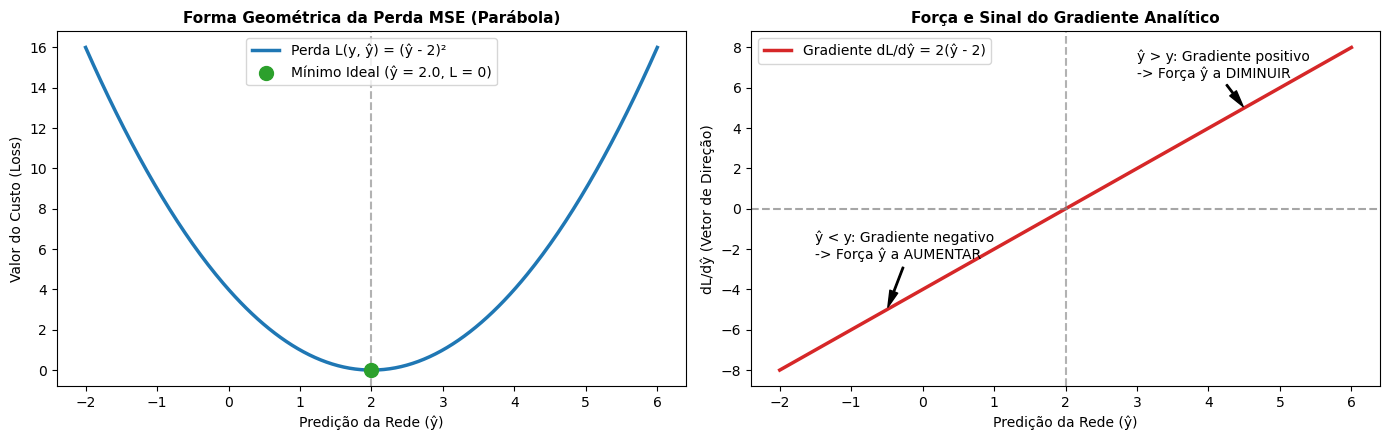

In [2]:
# Visualização 1D: A Parábola do MSE e o Sinal do Gradiente
mse = MSE()
y_fixo = np.array([[2.0]])  # Alvo real fixo em 2.0
y_preds = np.linspace(-2.0, 6.0, 300).reshape(-1, 1)

perdas_mse = [mse.calcular_custo(y_fixo, p.reshape(1, 1)) for p in y_preds]
gradientes_mse = [float(mse.gradiente(y_fixo, p.reshape(1, 1))[0, 0]) for p in y_preds]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(y_preds.ravel(), perdas_mse, color="#1f77b4", lw=2.5, label="Perda L(y, ŷ) = (ŷ - 2)²")
ax1.scatter([2.0], [0.0], color="#2ca02c", s=100, zorder=5, label="Mínimo Ideal (ŷ = 2.0, L = 0)")
ax1.axvline(2.0, color="gray", linestyle="--", alpha=0.6)
ax1.set_title("Forma Geométrica da Perda MSE (Parábola)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Predição da Rede (ŷ)")
ax1.set_ylabel("Valor do Custo (Loss)")
ax1.legend()

ax2.plot(y_preds.ravel(), gradientes_mse, color="#d62728", lw=2.5, label="Gradiente dL/dŷ = 2(ŷ - 2)")
ax2.axhline(0, color="gray", linestyle="--", alpha=0.7)
ax2.axvline(2.0, color="gray", linestyle="--", alpha=0.6)
ax2.annotate("ŷ > y: Gradiente positivo\n-> Força ŷ a DIMINUIR", xy=(4.5, 5), xytext=(3.0, 6.5),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))
ax2.annotate("ŷ < y: Gradiente negativo\n-> Força ŷ a AUMENTAR", xy=(-0.5, -5), xytext=(-1.5, -2.5),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))
ax2.set_title("Força e Sinal do Gradiente Analítico", fontsize=11, fontweight="bold")
ax2.set_xlabel("Predição da Rede (ŷ)")
ax2.set_ylabel("dL/dŷ (Vetor de Direção)")
ax2.legend()

plt.tight_layout()
plt.show()


### Simulação Interativa 2D: A Superfície de Custo nos Parâmetros $(w, b)$

Vamos simular um conjunto de dados gerado por uma reta $y = 2x + 1$ com ruído gaussiano.
Abaixo calculamos a perda MSE para uma grade de pesos $w \in [0, 4]$ e vieses $b \in [-1, 3]$ para visualizar a **bacia convexa** que o otimizador percorre durante o treinamento.


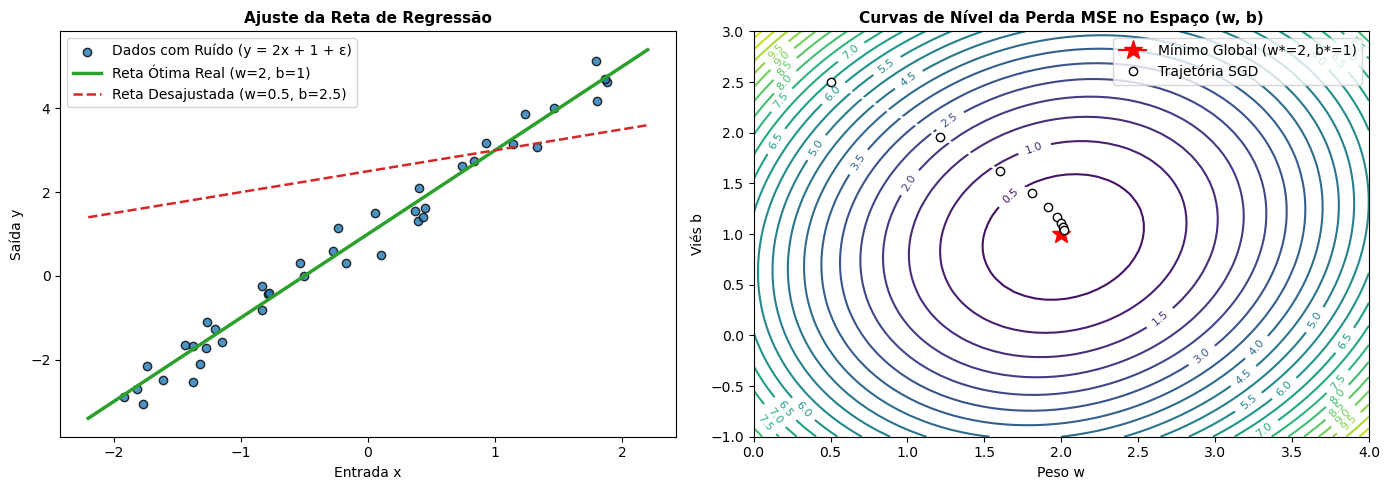

In [3]:
# Simulação: Superfície de Perda MSE no Espaço de Parâmetros (w, b)
rng = np.random.RandomState(42)
x_dados = rng.uniform(-2, 2, size=(40, 1))
y_dados = 2.0 * x_dados + 1.0 + rng.normal(0, 0.4, size=(40, 1))

w_grid = np.linspace(0.0, 4.0, 60)
b_grid = np.linspace(-1.0, 3.0, 60)
W_mesh, B_mesh = np.meshgrid(w_grid, b_grid)

Z_loss = np.zeros_like(W_mesh)
for i in range(W_mesh.shape[0]):
    for j in range(W_mesh.shape[1]):
        w_val = W_mesh[i, j]
        b_val = B_mesh[i, j]
        y_pred_temp = w_val * x_dados + b_val
        Z_loss[i, j] = mse.calcular_custo(y_dados, y_pred_temp)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Painel 1: Dados e Reta
ax1.scatter(x_dados, y_dados, color="#1f77b4", alpha=0.8, edgecolors='k', label="Dados com Ruído (y = 2x + 1 + ε)")
x_reta = np.linspace(-2.2, 2.2, 100)
ax1.plot(x_reta, 2.0 * x_reta + 1.0, color="#2ca02c", lw=2.5, label="Reta Ótima Real (w=2, b=1)")
ax1.plot(x_reta, 0.5 * x_reta + 2.5, color="#d62728", linestyle="--", lw=1.8, label="Reta Desajustada (w=0.5, b=2.5)")
ax1.set_title("Ajuste da Reta de Regressão", fontsize=11, fontweight="bold")
ax1.set_xlabel("Entrada x")
ax1.set_ylabel("Saída y")
ax1.legend()

# Painel 2: Curvas de Nível da Perda (Contour)
cp = ax2.contour(W_mesh, B_mesh, Z_loss, levels=25, cmap="viridis")
ax2.clabel(cp, inline=True, fontsize=8)
ax2.plot([2.0], [1.0], marker='*', color='red', markersize=14, label="Mínimo Global (w*=2, b*=1)")

# Trajetória simulada de gradiente
w_path, b_path = [0.5], [2.5]
lr = 0.15
for _ in range(8):
    y_p = w_path[-1] * x_dados + b_path[-1]
    err = y_p - y_dados
    dw = 2.0 * np.mean(err * x_dados)
    db = 2.0 * np.mean(err)
    w_path.append(w_path[-1] - lr * dw)
    b_path.append(b_path[-1] - lr * db)

ax2.plot(w_path, b_path, marker='o', color='white', markeredgecolor='black', lw=2, label="Trajetória SGD")
ax2.set_title("Curvas de Nível da Perda MSE no Espaço (w, b)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Peso w")
ax2.set_ylabel("Viés b")
ax2.legend()

plt.tight_layout()
plt.show()


## 2. BCE (Binary Cross-Entropy) — Para Classificação Binária

A Entropia Cruzada Binária é deduzida pelo princípio da **Máxima Verossimilhança** de uma distribuição de Bernoulli:
$$L(y, \hat{y}) = -\frac{1}{N} \sum_{i=1}^N \Big[ y_i \ln(\hat{y}_i) + (1 - y_i) \ln(1 - \hat{y}_i) \Big]$$

### Intuição da Teoria da Informação: A Medida da "Surpresa" ($-\ln(p)$)
- Se a resposta real é **$y = 1$**, a perda é $-\ln(\hat{y})$:
  - Se a rede prevê $\hat{y} = 0{,}99$ (99% de certeza no 1): $-\ln(0{,}99) \approx \mathbf{0{,}01}$ (surpresa quase zero, perda desprezível).
  - Se a rede prevê $\hat{y} = 0{,}01$ (disse que era 0 com 99% de certeza, mas era 1): $-\ln(0{,}01) \approx \mathbf{4{,}60}$ (choque/surpresa gigante, perda altíssima!).
- Se a resposta real é **$y = 0$**, a perda é $-\ln(1 - \hat{y})$ com comportamento análogo.

### A Grande Pergunta: Por que NÃO usar MSE para Classificação?
Abaixo mostramos visualmente o fenômeno do **congelamento do gradiente (*gradient saturation*)** do MSE em comparação com a estabilidade da BCE.


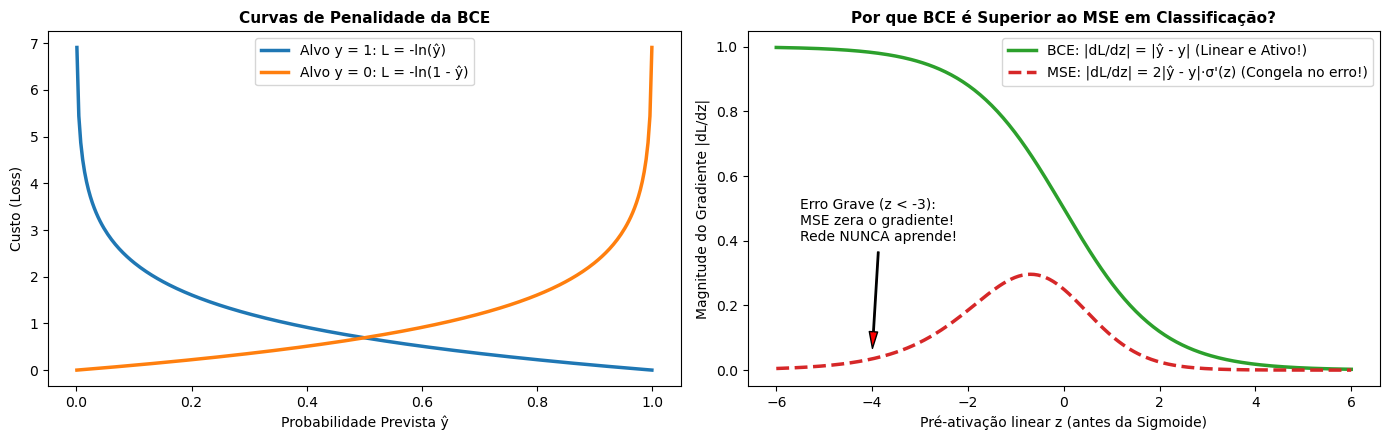

In [4]:
# Comparativo Crucial: Curva da BCE e Vantagem sobre o MSE
bce = BCE()
y_prob = np.linspace(0.001, 0.999, 300).reshape(-1, 1)

perda_bce_y1 = [bce.calcular_custo(np.array([[1.0]]), p.reshape(1, 1)) for p in y_prob]
perda_bce_y0 = [bce.calcular_custo(np.array([[0.0]]), p.reshape(1, 1)) for p in y_prob]

# Gradiente em relação a z (pré-ativação) antes da Sigmoide para alvo y = 1
z_vals = np.linspace(-6, 6, 300)
sig_vals = 1.0 / (1.0 + np.exp(-z_vals))
grad_bce_z = sig_vals - 1.0  # dL/dz = (ŷ - y) = σ(z) - 1
grad_mse_z = 2.0 * (sig_vals - 1.0) * (sig_vals * (1.0 - sig_vals))  # 2(ŷ - y) * σ'(z)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(y_prob.ravel(), perda_bce_y1, color="#1f77b4", lw=2.5, label="Alvo y = 1: L = -ln(ŷ)")
ax1.plot(y_prob.ravel(), perda_bce_y0, color="#ff7f0e", lw=2.5, label="Alvo y = 0: L = -ln(1 - ŷ)")
ax1.set_title("Curvas de Penalidade da BCE", fontsize=11, fontweight="bold")
ax1.set_xlabel("Probabilidade Prevista ŷ")
ax1.set_ylabel("Custo (Loss)")
ax1.legend()

ax2.plot(z_vals, np.abs(grad_bce_z), color="#2ca02c", lw=2.5, label="BCE: |dL/dz| = |ŷ - y| (Linear e Ativo!)")
ax2.plot(z_vals, np.abs(grad_mse_z), color="#d62728", lw=2.5, linestyle="--", label="MSE: |dL/dz| = 2|ŷ - y|·σ'(z) (Congela no erro!)")
ax2.annotate("Erro Grave (z < -3):\nMSE zera o gradiente!\nRede NUNCA aprende!", xy=(-4, 0.05), xytext=(-5.5, 0.4),
             arrowprops=dict(facecolor='red', shrink=0.05, width=1, headwidth=6))
ax2.set_title("Por que BCE é Superior ao MSE em Classificação?", fontsize=11, fontweight="bold")
ax2.set_xlabel("Pré-ativação linear z (antes da Sigmoide)")
ax2.set_ylabel("Magnitude do Gradiente |dL/dz|")
ax2.legend()

plt.tight_layout()
plt.show()


## 3. CCE (Categorical Cross-Entropy) — Para Classificação Multiclasse

Utilizada em problemas de $C \ge 3$ classes (ex.: classificar dígitos de 0 a 9):
$$L(y, \hat{y}) = -\frac{1}{N} \sum_{i=1}^N \sum_{c=1}^C y_{ic} \ln(\hat{y}_{ic})$$

### O que acontece quando os alvos são *One-Hot*?
Se uma imagem é da Classe 0, seu vetor alvo é $y = [1, 0, 0]$. Como multiplicar por 0 zera o termo, a soma inteira se reduz a:
$$L = -\ln(\hat{y}_{\text{classe correta}})$$

### A Magia da Combinação Softmax + CCE no Backward
Quando o gradiente da CCE ($-\frac{y}{\hat{y}}$) entra na camada Softmax ($S(z)$), a matriz Jacobiana da Softmax se combina perfeitamente e cancela o denominador:
$$\frac{\partial L}{\partial z_c} = \frac{1}{N} (\hat{y}_c - y_c)$$
- Para a **classe correta** ($y=1$): $\frac{\partial L}{\partial z} = \hat{y} - 1 < 0$ (o gradiente é **negativo**, forçando o logit da classe correta a **SUBIR**).
- Para as **classes erradas** ($y=0$): $\frac{\partial L}{\partial z} = \hat{y} - 0 > 0$ (o gradiente é **positivo**, forçando os logits das classes erradas a **DESCER**).


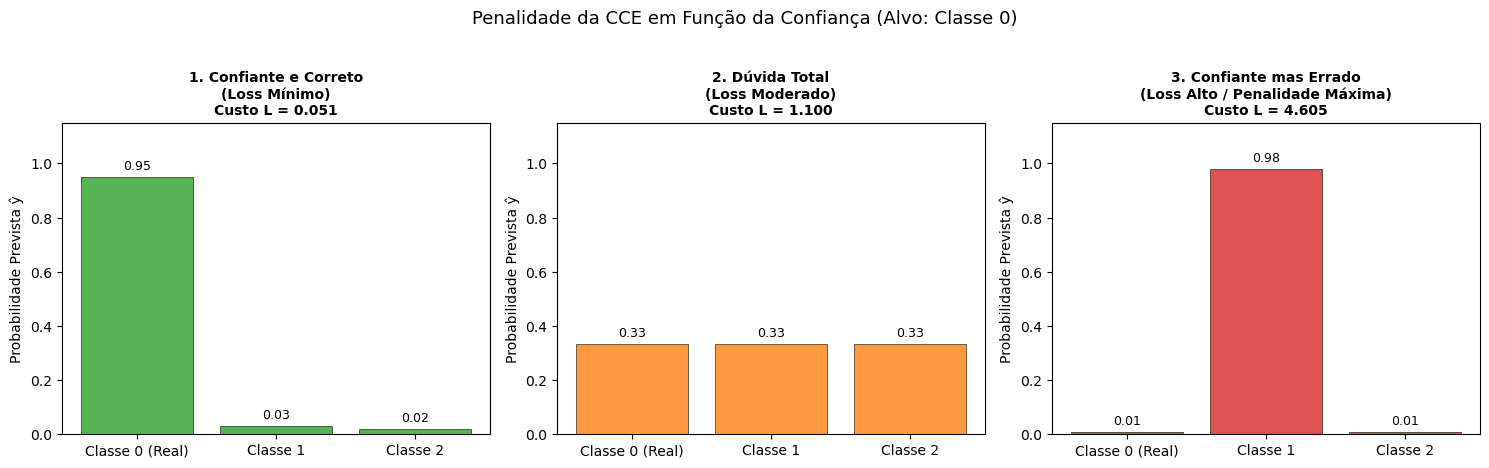

,Cenário,Probabilidade Classe Real,Perda CCE,Gradiente Classe Real (dL/dP_0)
0,1. Confiante e Correto (Loss Mínimo),0.950,0.0513,-1.05
1,2. Dúvida Total (Loss Moderado),0.333,1.0996,-3.00
2,3. Confiante mas Errado (Loss Alto / Penalidade Máxima),0.010,4.6052,-100.00


In [5]:
# Simulação de 3 Cenários Práticos de Classificação Multiclasse
cce = CCE()
y_true_cce = np.array([[1.0, 0.0, 0.0]])  # Alvo: Classe 0 é a correta

cenarios = {
    "1. Confiante e Correto\n(Loss Mínimo)": np.array([[0.95, 0.03, 0.02]]),
    "2. Dúvida Total\n(Loss Moderado)": np.array([[0.333, 0.333, 0.334]]),
    "3. Confiante mas Errado\n(Loss Alto / Penalidade Máxima)": np.array([[0.01, 0.98, 0.01]]),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
classes = ["Classe 0 (Real)", "Classe 1", "Classe 2"]
cores_cenarios = ["#2ca02c", "#ff7f0e", "#d62728"]
linhas_cce = []

for ax, (nome, pred), cor in zip(axes, cenarios.items(), cores_cenarios, strict=True):
    loss = cce.calcular_custo(y_true_cce, pred)
    grad = cce.gradiente(y_true_cce, pred)[0]

    linhas_cce.append(
        {
            "Cenário": nome.replace('\n', ' '),
            "Probabilidade Classe Real": f"{pred[0, 0]:.3f}",
            "Perda CCE": f"{loss:.4f}",
            "Gradiente Classe Real (dL/dP_0)": f"{grad[0]:.2f}",
        }
    )

    bars = ax.bar(classes, pred[0], color=cor, alpha=0.8, edgecolor="black", linewidth=0.5)
    ax.set_ylim(0, 1.15)
    ax.set_title(f"{nome}\nCusto L = {loss:.3f}", fontsize=10, fontweight="bold")
    ax.set_ylabel("Probabilidade Prevista ŷ")

    for bar in bars:
        h = bar.get_height()
        ax.annotate(
            f"{h:.2f}",
            xy=(bar.get_x() + bar.get_width() / 2, h),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

plt.suptitle("Penalidade da CCE em Função da Confiança (Alvo: Classe 0)", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

pd.DataFrame(linhas_cce)


## 4. Validação Rigorosa das Derivadas Analíticas (Gradiente vs. Diferenças Finitas)

Para garantir que não há erros de sinal, fatores constantes esquecidos ou problemas dimensionais, comparamos o retorno de `gradiente` com o gradiente numérico aproximado por diferenças finitas centrais:
$$\frac{\partial L_{\text{num}}}{\partial \hat{y}_{ij}} = \frac{L(\hat{y} + \epsilon e_{ij}) - L(\hat{y} - \epsilon e_{ij})}{2\epsilon}, \quad \text{com } \epsilon = 10^{-6}$$


In [6]:
resumo_gradientes = []
eps = 1e-6
rng = np.random.RandomState(42)

# 1. MSE
y_true_mse = rng.randn(4, 2)
y_pred_mse = rng.randn(4, 2)
grad_ana_mse = mse.gradiente(y_true_mse, y_pred_mse)
grad_num_mse = np.zeros_like(y_pred_mse)
for i in range(y_pred_mse.shape[0]):
    for j in range(y_pred_mse.shape[1]):
        yp_m = y_pred_mse.copy()
        yp_m[i, j] += eps
        yp_l = y_pred_mse.copy()
        yp_l[i, j] -= eps
        grad_num_mse[i, j] = (
            mse.calcular_custo(y_true_mse, yp_m) - mse.calcular_custo(y_true_mse, yp_l)
        ) / (2 * eps)
erro_mse = np.max(np.abs(grad_ana_mse - grad_num_mse))
resumo_gradientes.append(
    {
        "Função de Custo": "MSE",
        "Aplicação": "Regressão",
        "Max Erro Absoluto": f"{erro_mse:.2e}",
        "Concordância": "Excelente (< 1e-5)" if erro_mse < 1e-4 else "Atenção",
    }
)

# 2. BCE
y_true_bce = rng.randint(0, 2, size=(4, 1)).astype(np.float64)
y_pred_bce = rng.uniform(0.2, 0.8, size=(4, 1))
grad_ana_bce = bce.gradiente(y_true_bce, y_pred_bce)
grad_num_bce = np.zeros_like(y_pred_bce)
for i in range(y_pred_bce.shape[0]):
    yp_m = y_pred_bce.copy()
    yp_m[i, 0] += eps
    yp_l = y_pred_bce.copy()
    yp_l[i, 0] -= eps
    grad_num_bce[i, 0] = (
        bce.calcular_custo(y_true_bce, yp_m) - bce.calcular_custo(y_true_bce, yp_l)
    ) / (2 * eps)
erro_bce = np.max(np.abs(grad_ana_bce - grad_num_bce))
resumo_gradientes.append(
    {
        "Função de Custo": "BCE",
        "Aplicação": "Classificação Binária",
        "Max Erro Absoluto": f"{erro_bce:.2e}",
        "Concordância": "Excelente (< 1e-5)" if erro_bce < 1e-4 else "Atenção",
    }
)

# 3. CCE
y_true_cce_t = np.array([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0]])
y_pred_cce_t = np.array([[0.6, 0.3, 0.1], [0.2, 0.5, 0.3]])
grad_ana_cce = cce.gradiente(y_true_cce_t, y_pred_cce_t)
grad_num_cce = np.zeros_like(y_pred_cce_t)
for i in range(y_pred_cce_t.shape[0]):
    for j in range(y_pred_cce_t.shape[1]):
        yp_m = y_pred_cce_t.copy()
        yp_m[i, j] += eps
        yp_l = y_pred_cce_t.copy()
        yp_l[i, j] -= eps
        grad_num_cce[i, j] = (
            cce.calcular_custo(y_true_cce_t, yp_m) - cce.calcular_custo(y_true_cce_t, yp_l)
        ) / (2 * eps)
erro_cce = np.max(np.abs(grad_ana_cce - grad_num_cce))
resumo_gradientes.append(
    {
        "Função de Custo": "CCE",
        "Aplicação": "Classificação Multiclasse",
        "Max Erro Absoluto": f"{erro_cce:.2e}",
        "Concordância": "Excelente (< 1e-5)" if erro_cce < 1e-4 else "Atenção",
    }
)

pd.DataFrame(resumo_gradientes)


,Função de Custo,Aplicação,Max Erro Absoluto,Concordância
0,MSE,Regressão,5.10e-10,Excelente (< 1e-5)
1,BCE,Classificação Binária,6.37e-11,Excelente (< 1e-5)
2,CCE,Classificação Multiclasse,2.88e-11,Excelente (< 1e-5)


---

## 5. Perguntas Típicas da Arguição Oral (Guia de Defesa)

### Q1: Por que não usamos MSE para treinar classificação binária com Sigmoide?
- **Resposta:** Porque a derivada da Sigmoide $\sigma'(z) = \sigma(z)(1 - \sigma(z))$ satura e vai a zero quando $|z|$ é grande. Se a rede cometer um erro grave (ex.: $y = 1$, mas $z = -5 \implies \hat{y} \approx 0$), o gradiente do MSE multiplica por $\sigma'(z) \approx 0$, congelando o aprendizado (*vanishing gradient* no erro). Com a BCE, a derivada da perda divide exatamente por $\hat{y}(1 - \hat{y})$, cancelando a derivada da Sigmoide e gerando um sinal forte linear $(\hat{y} - y) \approx -1$, que corrige o neurônio imediatamente.

### Q2: Por que precisamos de clipping ($\,\epsilon = 10^{-15}\,)$ na BCE e CCE?
- **Resposta:** Porque a função $\ln(x)$ diverge para $-\infty$ quando $x \to 0$. Se a rede prever probabilidade exatamente $0{,}0$ para a classe correta, $\ln(0)$ gerará `-inf`, e operações posteriores produzirão `NaN`, corrompendo irreversivelmente todos os pesos da rede neural.

### Q3: Qual a relação entre a CCE e a Softmax na última camada?
- **Resposta:** Elas foram matematicamente feitas uma para a outra. A CCE é a log-verossimilhança negativa de uma distribuição multinomial parametrizada por exponenciais normalizadas (Softmax). A derivada do custo em relação aos logits (entradas pré-ativação da Softmax) resulta na fórmula elegante e compacta $\frac{\partial L}{\partial z_c} = \frac{1}{N}(\hat{y}_c - y_c)$.
